In [1]:
# 丁香花数据集course-9-syringa.csv，
# 丁香花数据集包含 daphne，syringa 和 willow 等 3 个种类，其中每个种类包含 150 条数据，
# 每条数据包含 4 个特征值：花萼长度，花萼宽度，花瓣长度，花瓣宽度

In [ ]:
# 下载数据集
import requests
url = 'https://labfile.oss.aliyuncs.com/courses/1081/course-9-syringa.csv'
response = requests.get(url)
if response.status_code == 200:
   with open('syringa.csv', 'wb') as file:
       file.write(response.content)
   print("数据下载成功")
else:
   print(f"请求失败，状态码：{response.status_code}")


In [2]:
import pandas as pd
df = pd.read_csv('syringa.csv')
print(df.head())
# 打印labels的唯一值
print(df['labels'].unique())

   sepal_length  sepal_width  petal_length  petal_width  labels
0           5.1          3.5           2.4          2.1  daphne
1           4.9          3.0           2.7          1.7  daphne
2           4.7          3.2           2.2          1.4  daphne
3           4.6          3.1           1.6          1.7  daphne
4           5.0          3.6           1.6          1.4  daphne
['daphne' 'syringa' 'willow ']


In [3]:
# 分离特征变量和目标变量
features = df.columns.tolist()
features.remove('labels') 
X = df[features]
print("特征查看：\n", X.describe())
y = df['labels']
print("目标值查看：\n", y.describe())

特征查看：
        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.669333     3.054000      3.731333     1.874667
std        0.702053     0.433594      1.125372     0.434144
min        4.200000     2.000000      1.400000     0.500000
25%        5.100000     2.800000      2.850000     1.600000
50%        5.650000     3.000000      4.100000     1.900000
75%        6.100000     3.300000      4.500000     2.200000
max        7.500000     4.400000      6.200000     3.000000
目标值查看：
 count        150
unique         3
top       daphne
freq          50
Name: labels, dtype: object


In [4]:
# 分离训练集和测试集
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("训练集大小:", X_train.shape)
print("测试集大小:", X_test.shape)

训练集大小: (120, 4)
测试集大小: (30, 4)


In [5]:
# 使用KNN分类器进行训练和预测
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [6]:
# 评估模型性能
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
print("准确率:", accuracy)
print("分类报告:\n", classification_report(y_test, y_pred))
print("混淆矩阵:\n", confusion_matrix(y_test, y_pred))

准确率: 0.8666666666666667
分类报告:
               precision    recall  f1-score   support

      daphne       1.00      1.00      1.00        10
     syringa       0.73      0.89      0.80         9
     willow        0.89      0.73      0.80        11

    accuracy                           0.87        30
   macro avg       0.87      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30

混淆矩阵:
 [[10  0  0]
 [ 0  8  1]
 [ 0  3  8]]


分析数据

In [7]:
# 将labels列进行数值编码
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['labels'] = le.fit_transform(df['labels'])
print("编码后的标签查看：\n", df['labels'].unique())
# 打印labels列的字符串与数值对应关系
print("编码前后的对应关系：")
for i, class_name in enumerate(le.classes_):
    print(f"原始标签: '{class_name}' -> 编码值: {i}")

编码后的标签查看：
 [0 1 2]
编码前后的对应关系：
原始标签: 'daphne' -> 编码值: 0
原始标签: 'syringa' -> 编码值: 1
原始标签: 'willow ' -> 编码值: 2


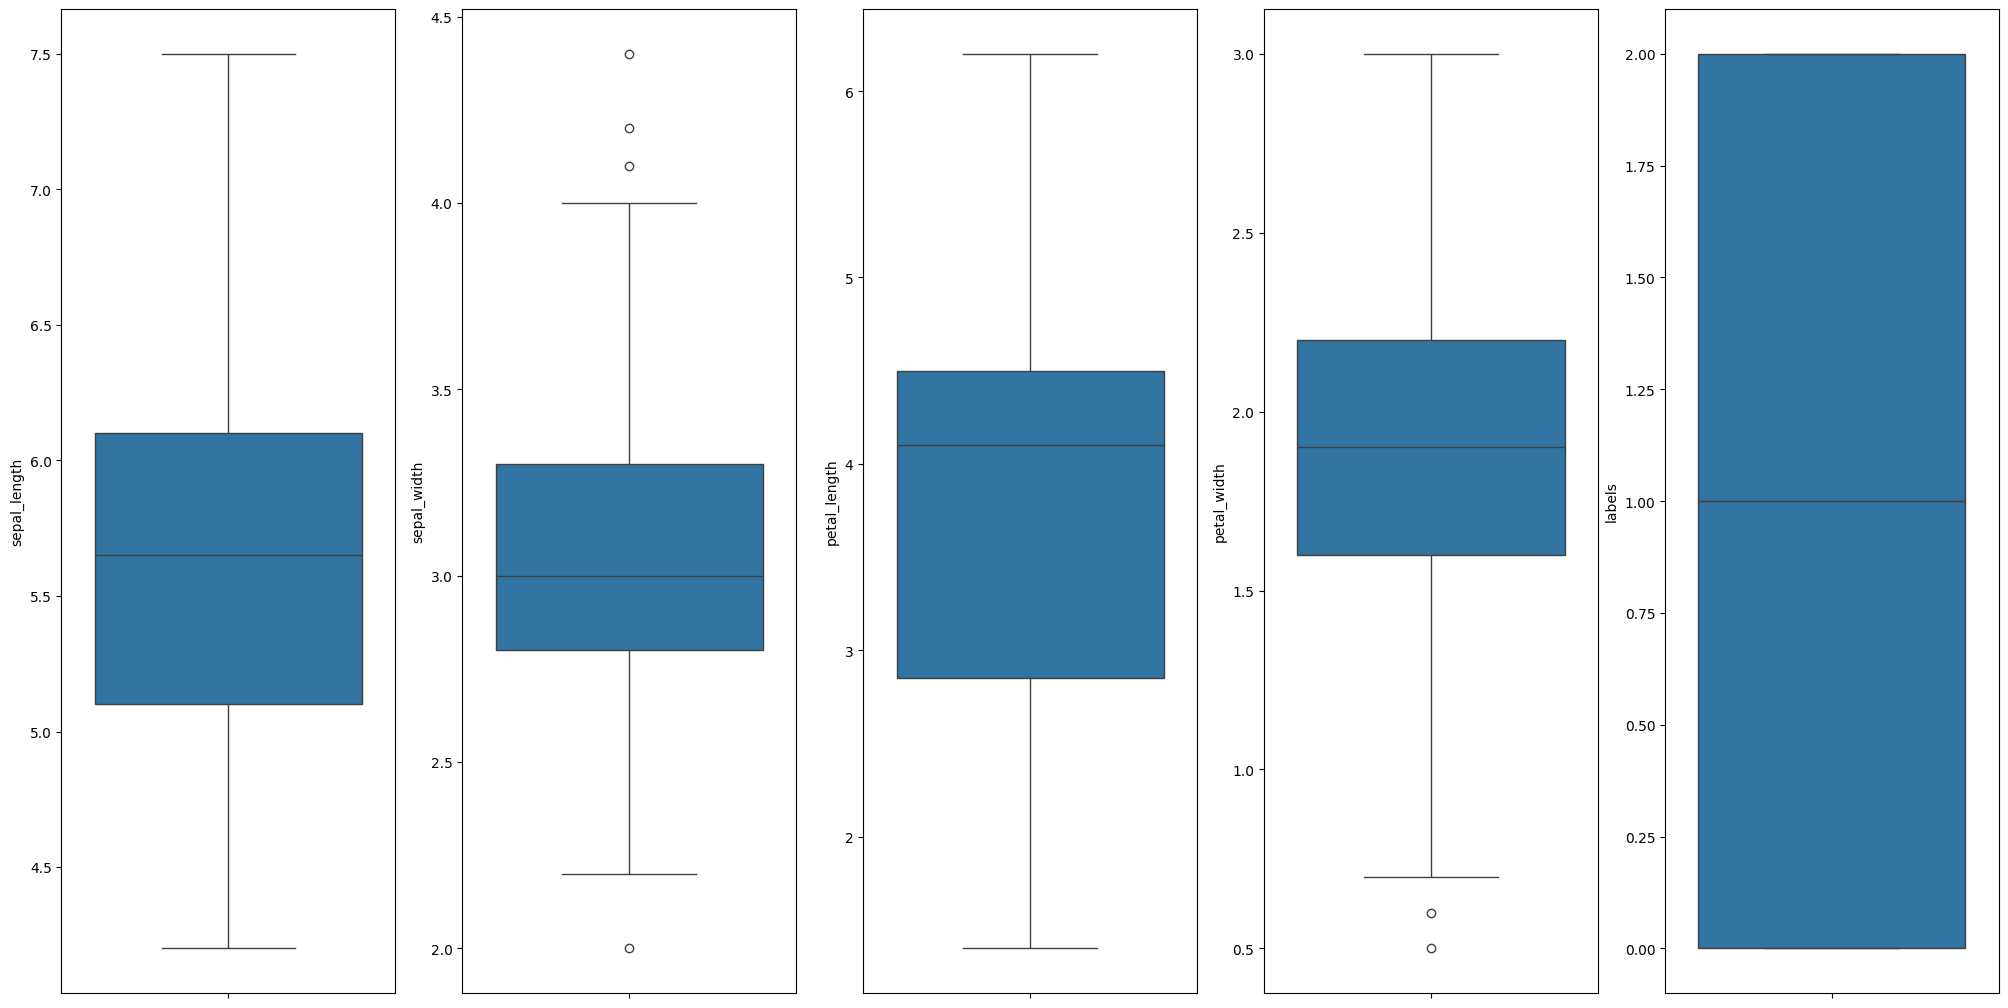

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 设置2行7列的子图网格，尺寸为20x10，每个子图绘制一个特征的箱线图
fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(20, 10))
# 将二维的子图数组（形状为2行7列）转换为一维数组（长度为14），方便通过索引逐个访问每个子图
axs = axs.flatten()

# 循环遍历df的每一列（k是列名，v是列数据）。对每一列，绘制箱线图：
# y=k指定箱线图的y轴数据为当前列k的值。
# data=df指定数据源为 df。
# ax=axs[index]将箱线图绘制到对应的子图上（通过索引index访问展平后的子图数组）。
# 每次循环后，index += 1递增索引，移动到下一个子图。
index = 0
for k, v in df.items():
    sns.boxplot(y=k, data=df, ax=axs[index])
    index += 1

# 自动调整子图之间的间距，避免重叠：
# pad=0.4设置图形边缘与子图之间的内边距。
# w_pad=0.5设置子图之间的水平间距。
# h_pad=5.0设置子图之间的垂直间距。
# plt.show()最终显示生成的图形。
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [9]:
# 异常值很少

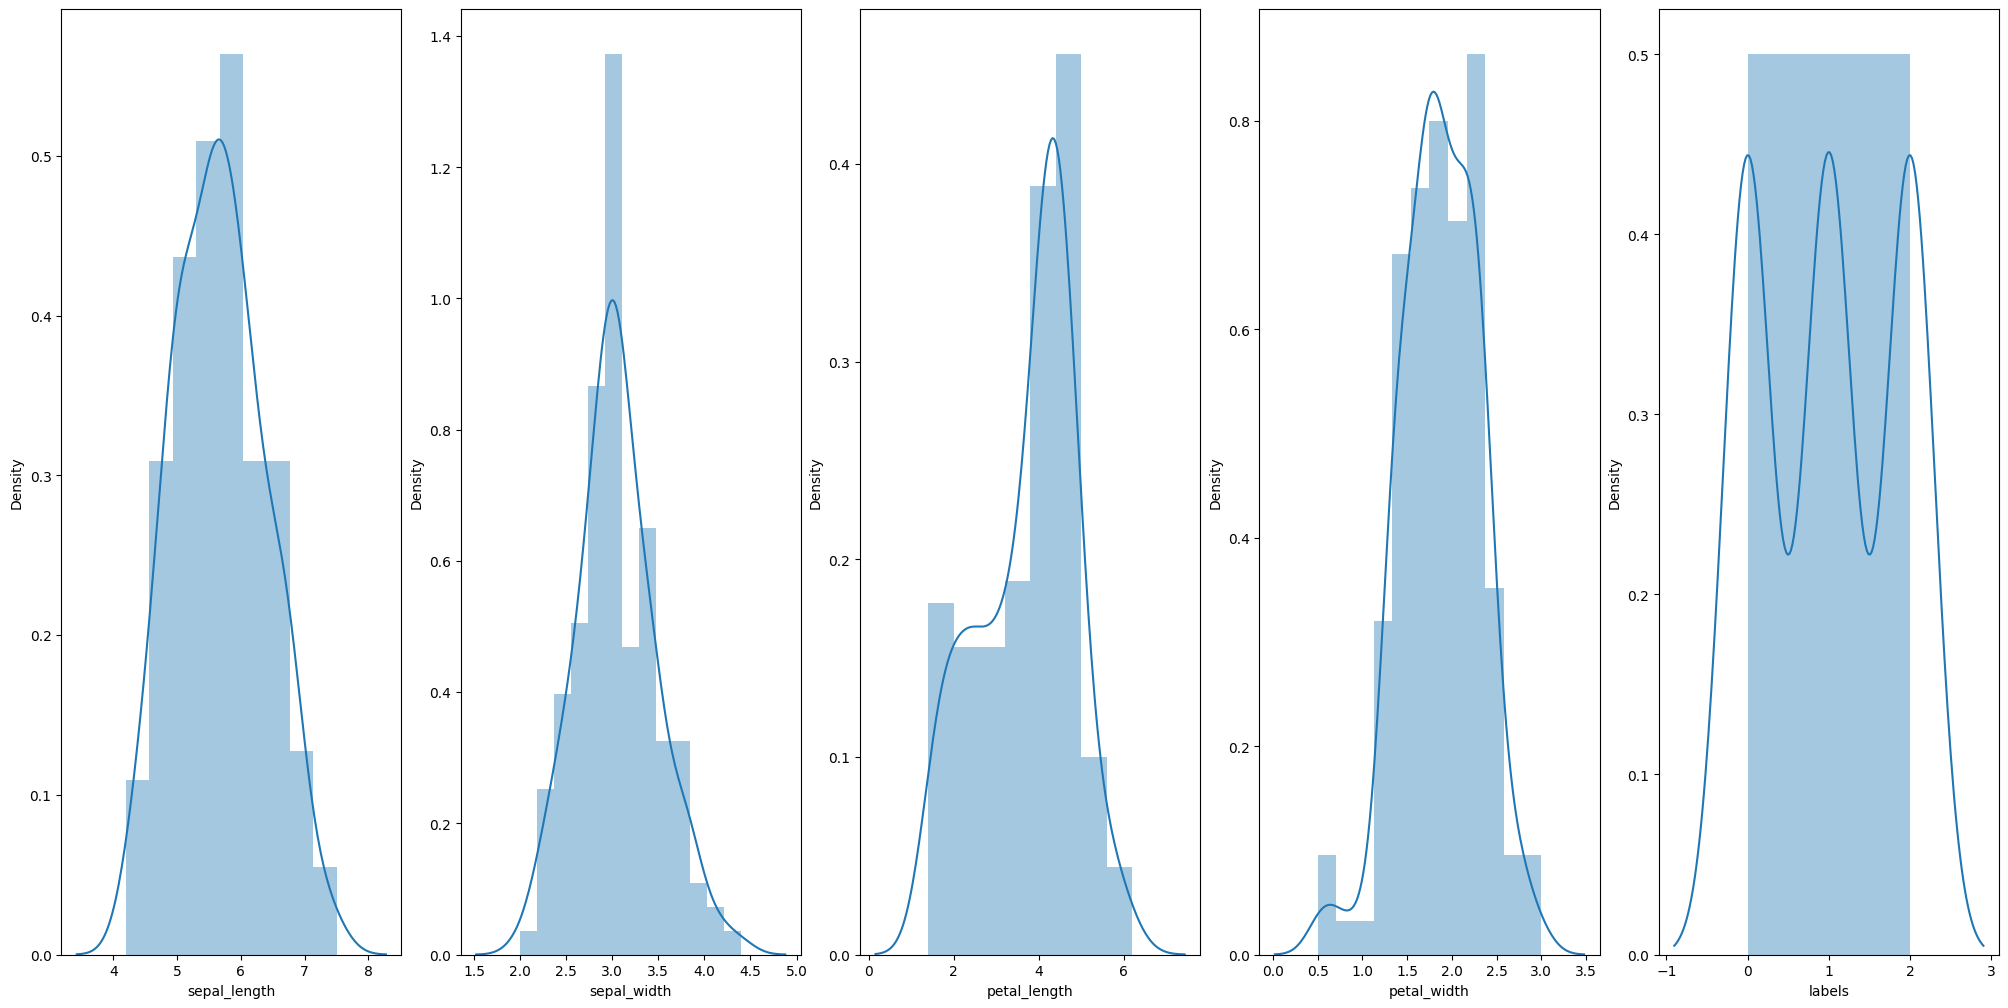

In [10]:
import warnings
warnings.filterwarnings("ignore")

fig, axs = plt.subplots(ncols=5,nrows=1, figsize=(20,10))
axs = axs.flatten()
index = 0
for k, v in df.items():
    sns.distplot(v, ax=axs[index])
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

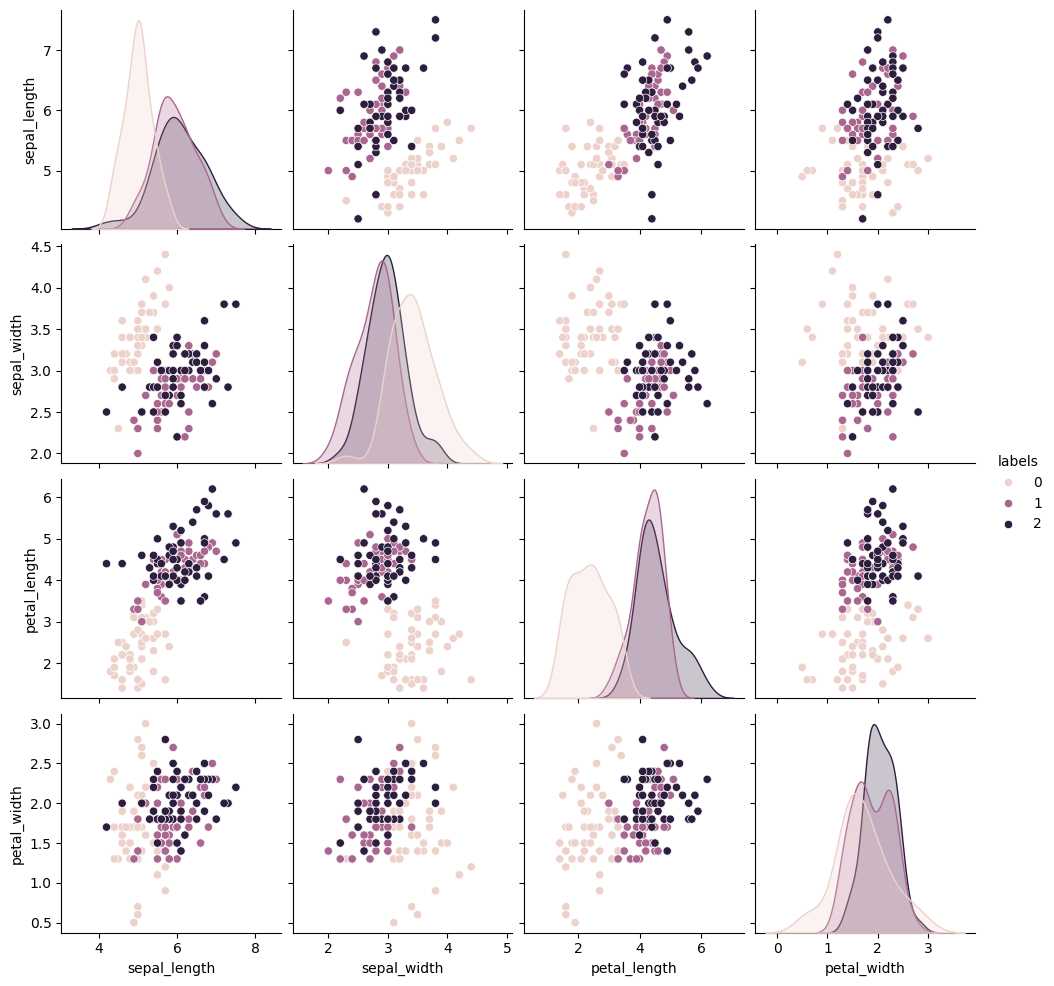

In [11]:
# 绘制数据集
import matplotlib.pyplot as plt
import seaborn as sns
# 使用seaborn的pairplot绘制特征两两之间的关系，并根据标签上色
sns.pairplot(df, hue='labels')
plt.show()

<Axes: >

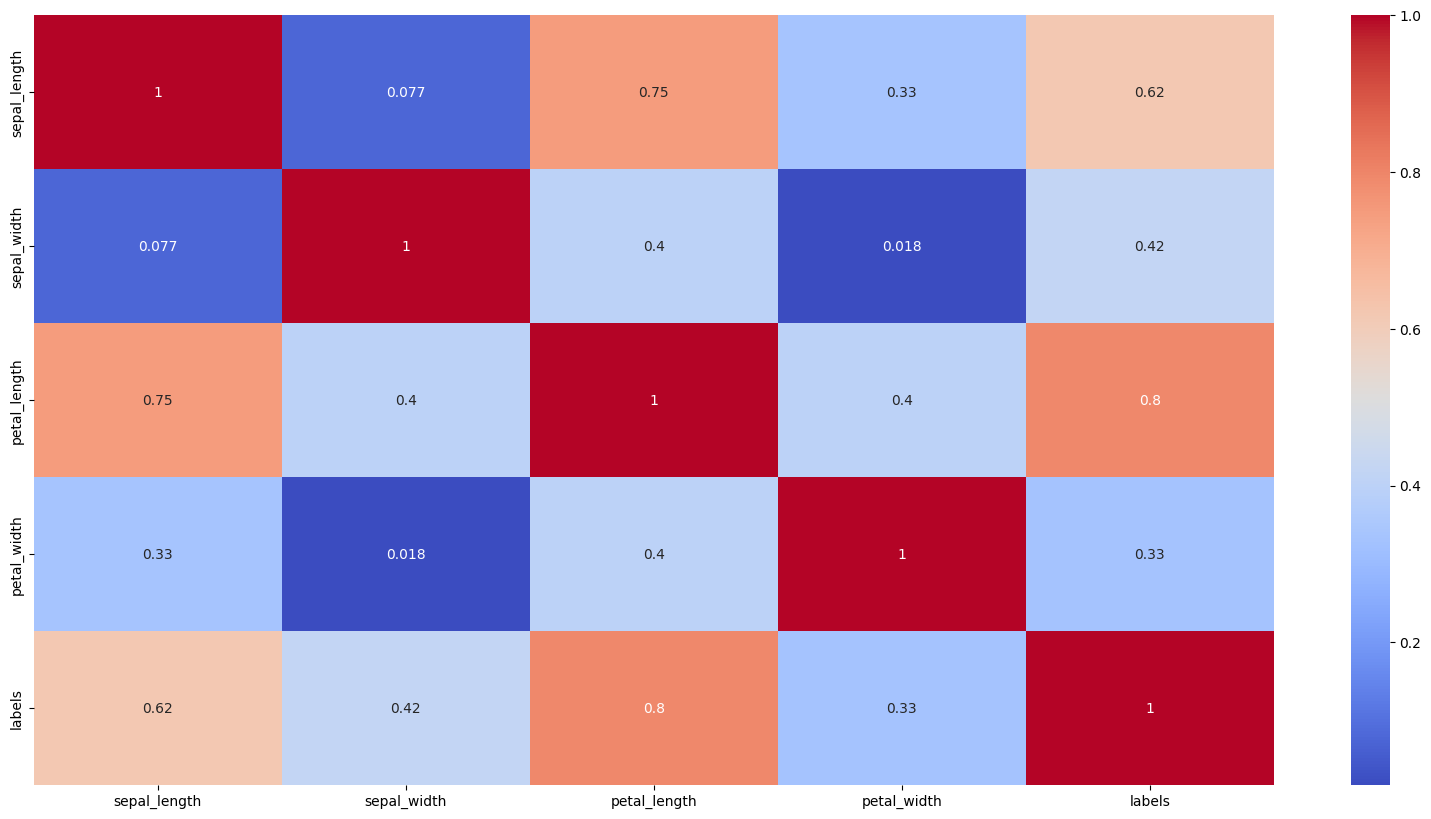

In [12]:
# 然后绘制数据的两两相关性
plt.figure(figsize=(20,10))
sns.heatmap(df.corr().abs(), annot=True, cmap='coolwarm')

In [13]:
from sklearn import preprocessing

# 创建MinMaxScaler对象，用于将数据缩放到指定范围（默认[0, 1]）。这种标准化方法能消除量纲影响，使不同特征具有可比性
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(X)
# 将缩放后的NumPy数组转换回Pandas DataFrame，并保留原列名，便于后续处理
X_scaled = pd.DataFrame(x_scaled, columns=X.columns)
print("缩放后的特征查看：\n", X_scaled.describe())

缩放后的特征查看：
        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       0.445253     0.439167      0.485694     0.549867
std        0.212743     0.180664      0.234452     0.173658
min        0.000000     0.000000      0.000000     0.000000
25%        0.272727     0.333333      0.302083     0.440000
50%        0.439394     0.416667      0.562500     0.560000
75%        0.575758     0.541667      0.645833     0.680000
max        1.000000     1.000000      1.000000     1.000000


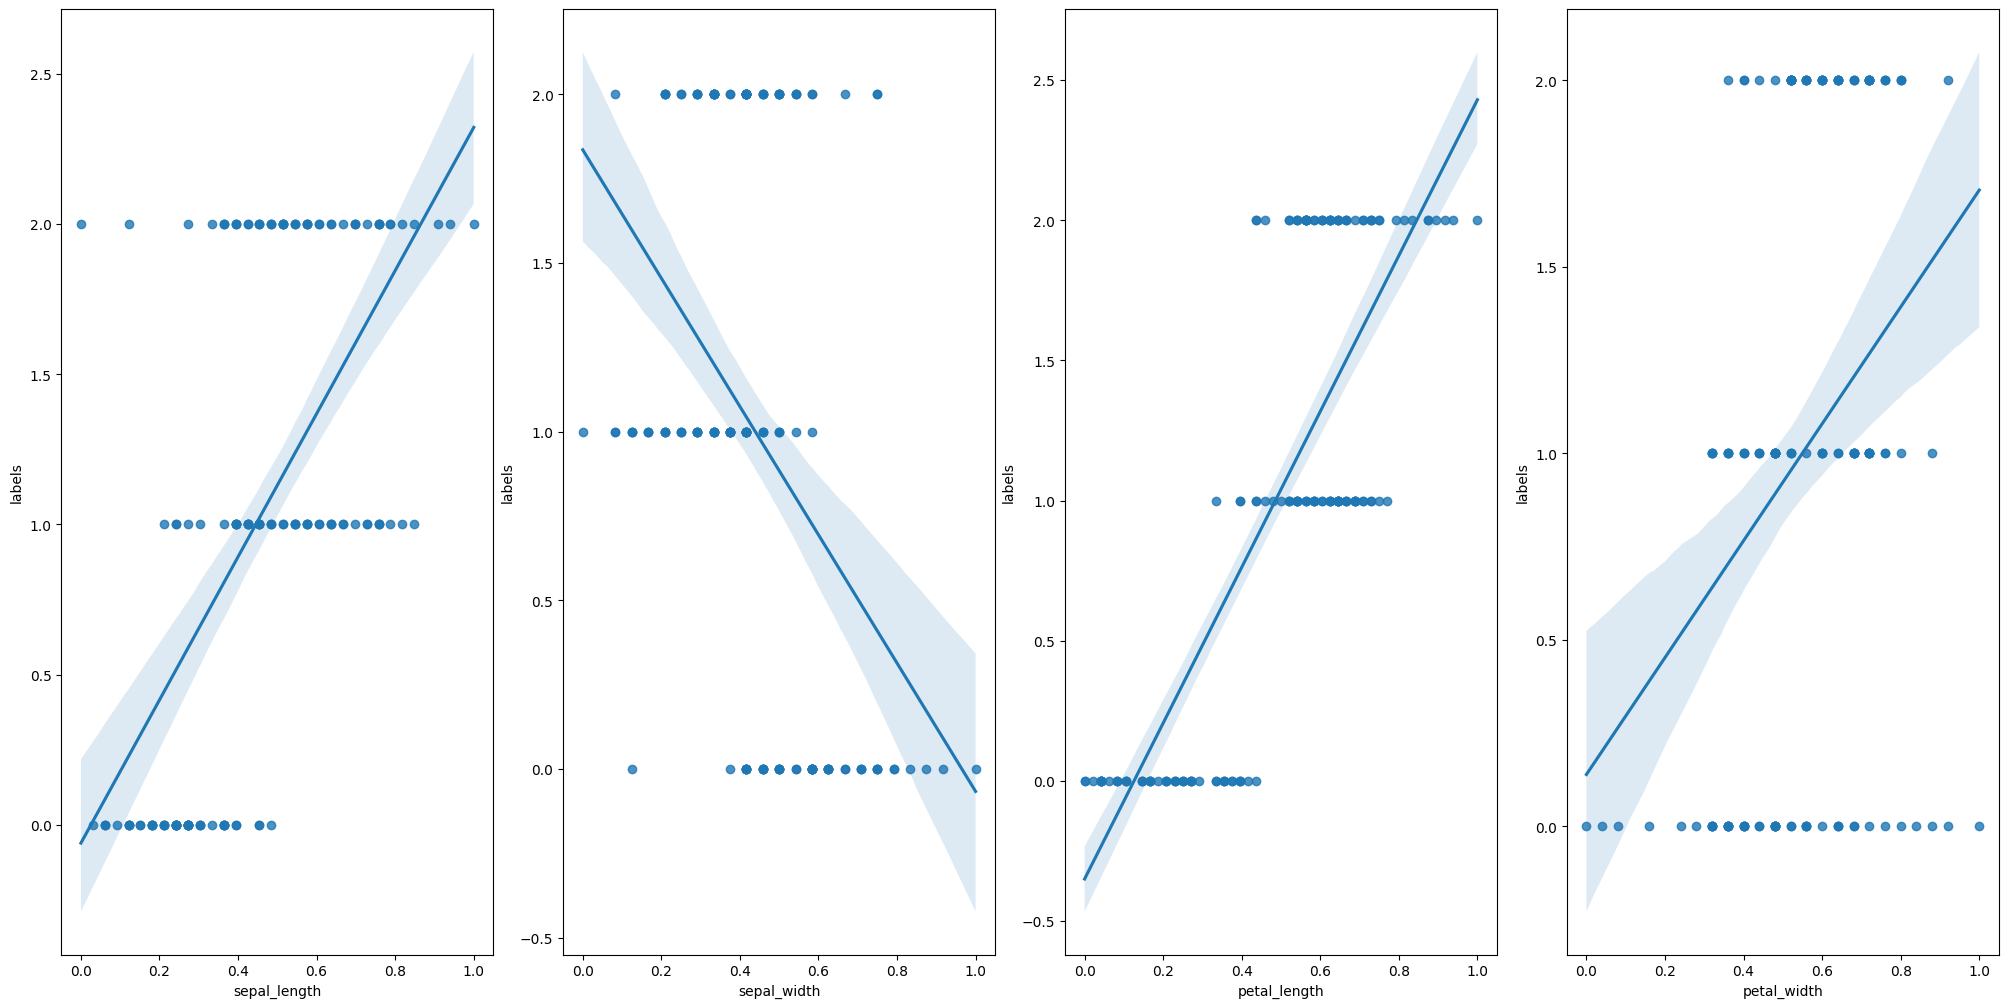

In [15]:
y = df['labels']
# 绘制标准化后特征与目标变量的回归图
fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(20,10))
axs = axs.flatten()
index = 0
for k in X.columns:
    sns.regplot(y=y, x=X_scaled[k], ax=axs[index])
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [17]:
# KNN分类器训练和评估
from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

kf = KFold(n_splits=5, shuffle=True, random_state=42)
# 尝试不同的K值，找到最佳K值
k_values = range(1, 21)
best_k = 1
best_accuracy = 0.0
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    y_pred = cross_val_predict(knn, X_scaled, y, cv=kf)
    accuracy = accuracy_score(y, y_pred)
    print(f"K={k} 时的准确率: {accuracy}")
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_k = k
print(f"最佳K值: {best_k}，对应的准确率: {best_accuracy}")


K=1 时的准确率: 0.7533333333333333
K=2 时的准确率: 0.74
K=3 时的准确率: 0.78
K=4 时的准确率: 0.7266666666666667
K=5 时的准确率: 0.78
K=6 时的准确率: 0.7
K=7 时的准确率: 0.74
K=8 时的准确率: 0.7266666666666667
K=9 时的准确率: 0.7666666666666667
K=10 时的准确率: 0.7333333333333333
K=11 时的准确率: 0.72
K=12 时的准确率: 0.72
K=13 时的准确率: 0.7266666666666667
K=14 时的准确率: 0.6866666666666666
K=15 时的准确率: 0.7
K=16 时的准确率: 0.7
K=17 时的准确率: 0.7066666666666667
K=18 时的准确率: 0.6866666666666666
K=19 时的准确率: 0.7
K=20 时的准确率: 0.6933333333333334
最佳K值: 3，对应的准确率: 0.78


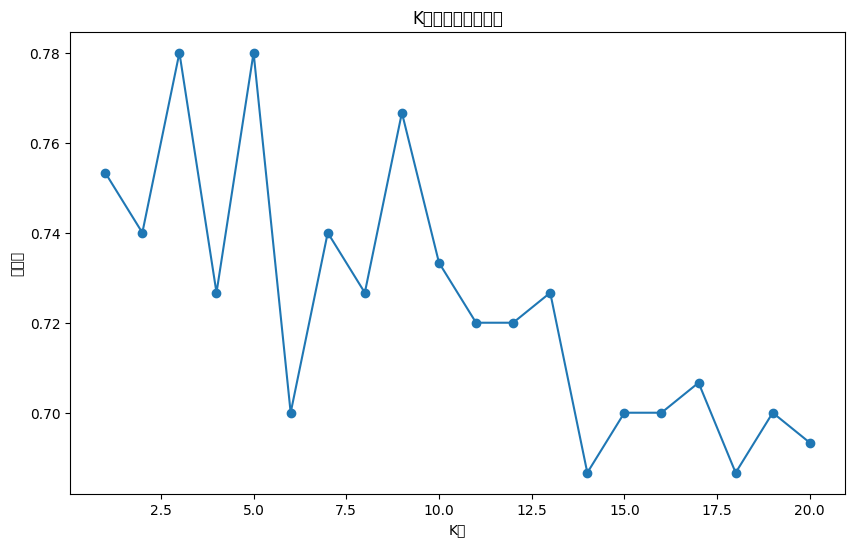

In [19]:
# 绘图显示不同K值的准确率变化
accuracies = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    y_pred = cross_val_predict(knn, X_scaled, y, cv=kf)
    accuracy = accuracy_score(y, y_pred)
    accuracies.append(accuracy)
plt.figure(figsize=(10,6))
plt.plot(k_values, accuracies, marker='o')
plt.title('K值与准确率关系图')
plt.xlabel('K值')
plt.ylabel('准确率')
plt.show()

In [18]:
# 使用最佳K值进行最终训练和评估
knn = KNeighborsClassifier(n_neighbors=best_k)
scores = cross_val_predict(knn, X_scaled, y, cv=kf)
print("最终模型评估：")
print("准确率:", accuracy_score(y, scores))
print("分类报告:\n", classification_report(y, scores))
print("混淆矩阵:\n", confusion_matrix(y, scores))

最终模型评估：
准确率: 0.78
分类报告:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        50
           1       0.65      0.72      0.69        50
           2       0.71      0.64      0.67        50

    accuracy                           0.78       150
   macro avg       0.78      0.78      0.78       150
weighted avg       0.78      0.78      0.78       150

混淆矩阵:
 [[49  1  0]
 [ 1 36 13]
 [ 0 18 32]]


In [20]:
# 采用KDTree算法进行KNN分类器
knn = KNeighborsClassifier(n_neighbors=best_k, algorithm='kd_tree')
scores = cross_val_predict(knn, X_scaled, y, cv=kf)
print("使用KDTree加速后的模型评估：")
print("准确率:", accuracy_score(y, scores))
print("分类报告:\n", classification_report(y, scores))
print("混淆矩阵:\n", confusion_matrix(y, scores))

使用KDTree加速后的模型评估：
准确率: 0.78
分类报告:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98        50
           1       0.65      0.72      0.69        50
           2       0.71      0.64      0.67        50

    accuracy                           0.78       150
   macro avg       0.78      0.78      0.78       150
weighted avg       0.78      0.78      0.78       150

混淆矩阵:
 [[49  1  0]
 [ 1 36 13]
 [ 0 18 32]]
